In [146]:
import numpy as np
from astropy.io import fits
from matplotlib import pyplot
import pandas as pd
import os
import copy

from sklearn.mixture import GaussianMixture

import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')

import dio3
import multi_fgl_utils as util


In [147]:

if 1:
    import importlib
    importlib.reload(util);
np.set_printoptions(precision=4)

In [154]:
save_plots = 1
save_png = 1
plots_folder = '../plots/pop_study/HCU/'
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)



cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF'
    case = '4FGL-DR4_GMM_RF_no_prune'
elif cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF'
    case = '4FGL-DR3_GMM_RF'

baseline = (case == baseline_case)
root_folder = '../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)



In [155]:
xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)



In [156]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1'],
      dtype='object')

In [157]:
#xfeature = 'log10(Signif_Avg)'
xfeature = 'LP_SigCurv'
yfeature = 'LP_beta'

In [158]:
unas_classes = ['unas', 'unk']
extra_classes = ['msp', 'psr', 'glc']
class_name = 'CLASS1'
nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
assoc_classes = list(nsrc_dict.keys())
for cls in extra_classes:
    assoc_classes.remove(cls)
unas_mask = util.get_cl_mask(unas_classes, xdf, cname=class_name)
assoc_mask = util.get_cl_mask(assoc_classes, xdf, cname=class_name)
mask_dict = {'Unas': unas_mask, 'Assoc': assoc_mask, }

for cls in extra_classes:
    mask = util.get_cl_mask([cls], xdf, cname=class_name)
    mask_dict[cls] = mask

/Users/Dmitry/miniconda3/envs/tf/lib/python3.10/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


save figure to file: ../plots/pop_study/HCU//4FGL-DR4_LP_SigCurv_LP_beta_scatter.pdf


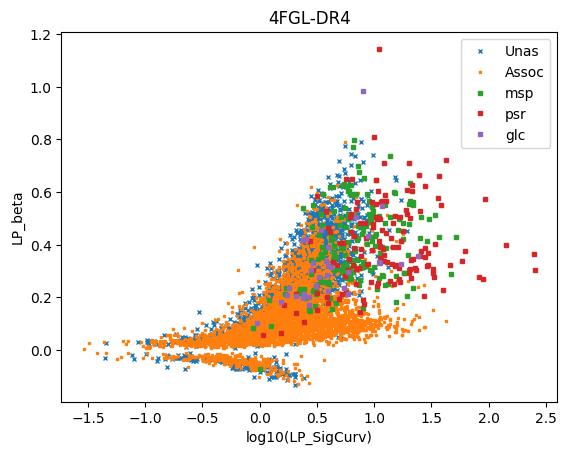

In [159]:
pyplot.figure()
for name, mask in mask_dict.items():
    xs = xdf[mask][xfeature]
    if xfeature == 'LP_SigCurv':
        xs = np.log10(xs)
    ys = xdf[mask][yfeature]
    marker = 's'
    ms = 2.5
    if name == 'Unas':
        marker = 'x'
    if name == 'Assoc':
        ms = 2
    pyplot.plot(xs, ys, ls='', marker=marker, label=name, ms=ms)
if xfeature == 'LP_SigCurv':
    pyplot.xlabel('log10(%s)' % xfeature)
else:
    pyplot.xlabel(xfeature)
pyplot.ylabel(yfeature)
pyplot.legend()
pyplot.title(cat_name)

if save_plots:
    fn = '%s/%s_%s_%s_scatter.pdf' % (plots_folder, cat_name, xfeature, yfeature)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn)
    if save_png:
        pyplot.savefig(fn.replace('.pdf', '.png'))